In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

RANDOM_STATE = 42


In [2]:
housing = fetch_california_housing(as_frame=True)

X = housing.data.copy()
y = housing.target.copy()

df = X.copy()
df["MedHouseVal"] = y

print("Dataset shape:", df.shape)
display(df.head())
print("\\nDataset information:")
df.info()


Dataset shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


\nDataset information:
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


Missing values per feature:


,Missing count
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0


Total missing feature values: 0
\nTarget summary:


count    20640.000000
mean         2.068558
std          1.153956
min          0.149990
25%          1.196000
50%          1.797000
75%          2.647250
max          5.000010
Name: MedHouseVal, dtype: float64

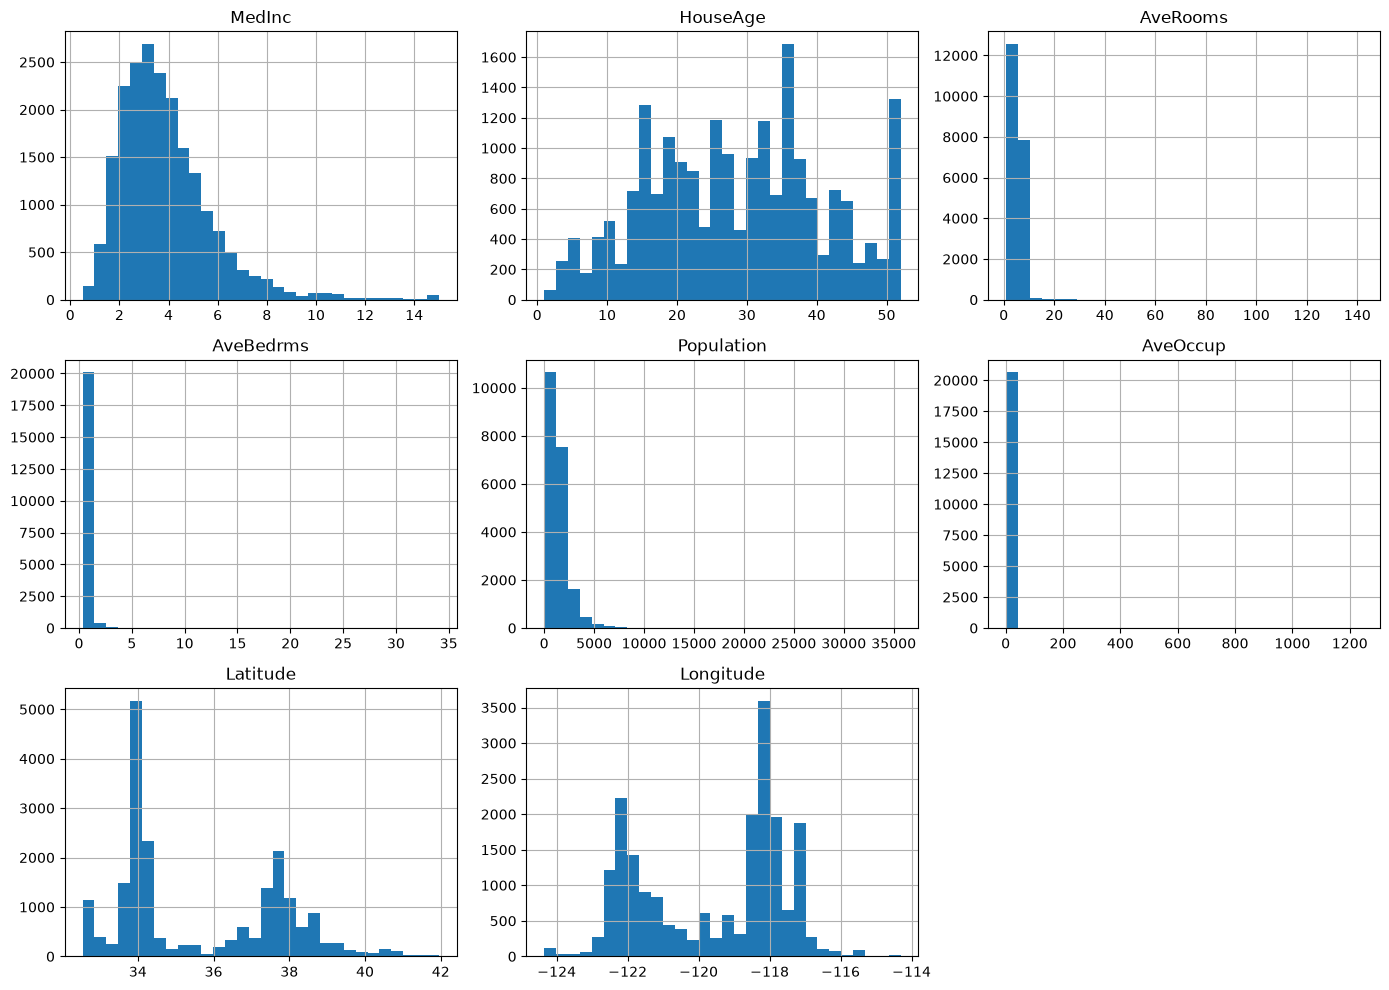

In [3]:
missing = X.isnull().sum()
print("Missing values per feature:")
display(missing.to_frame("Missing count"))

print("Total missing feature values:", int(missing.sum()))

print("\\nTarget summary:")
display(y.describe())

# Optional: inspect feature distributions
X.hist(figsize=(14, 10), bins=30)
plt.tight_layout()
plt.show()


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)


Training features: (16512, 8)
Testing features: (4128, 8)


In [12]:
# Preprocessing pipelines
scaled_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

tree_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Each model is placed in a pipeline so preprocessing is fitted on training data only.
models = {
    "Linear Regression": Pipeline(steps=[
        ("preprocess", scaled_preprocessor),
        ("model", LinearRegression())
    ]),
    "Decision Tree": Pipeline(steps=[
        ("preprocess", tree_preprocessor),
        ("model", DecisionTreeRegressor(random_state=RANDOM_STATE))
    ]),
    "Random Forest": Pipeline(steps=[
        ("preprocess", tree_preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1
        ))
    ]),
    "Gradient Boosting": Pipeline(steps=[
        ("preprocess", tree_preprocessor),
        ("model", GradientBoostingRegressor(random_state=RANDOM_STATE))
    ]),
    "Support Vector Regressor": Pipeline(steps=[
        ("preprocess", scaled_preprocessor),
        ("model", SVR(kernel="rbf", C=10, epsilon=0.1))
    ])
}


In [6]:
results = []
trained_models = {}

for name, pipeline in models.items():
    print(f"Training {name}...")
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    results.append({
        "Model": name,
        "MSE": mean_squared_error(y_test, predictions),
        "MAE": mean_absolute_error(y_test, predictions),
        "R2": r2_score(y_test, predictions)
    })
    trained_models[name] = pipeline

results_df = pd.DataFrame(results).sort_values(
    by="R2", ascending=False
).reset_index(drop=True)

display(results_df.round(4))


Training Linear Regression...
Training Decision Tree...
Training Random Forest...
Training Gradient Boosting...
Training Support Vector Regressor...


,Model,MSE,MAE,R2
0,Random Forest,0.2560,0.3277,0.8046
1,Gradient Boosting,0.2940,0.3716,0.7756
2,Support Vector Regressor,0.3237,0.3774,0.7530
3,Decision Tree,0.4943,0.4542,0.6228
4,Linear Regression,0.5559,0.5332,0.5758


In [7]:
best_model = results_df.iloc[0]
worst_model = results_df.iloc[-1]

print("Best-performing model (highest test R2):")
print(best_model.to_string())

print("\\nWorst-performing model (lowest test R2):")
print(worst_model.to_string())

print("\\nInterpretation:")
print(
    f"{best_model['Model']} performed best on this test split because it "
    f"achieved the highest R2 ({best_model['R2']:.4f}) and its error metrics "
    f"should be compared with the other models."
)
print(
    f"{worst_model['Model']} performed worst by test R2 "
    f"({worst_model['R2']:.4f}). This indicates it explained the least "
    f"variation in the unseen target values among the tested models."
)


Best-performing model (highest test R2):
Model    Random Forest
MSE           0.256022
MAE           0.327731
R2            0.804624
\nWorst-performing model (lowest test R2):
Model    Linear Regression
MSE               0.555892
MAE                 0.5332
R2                0.575788
\nInterpretation:
Random Forest performed best on this test split because it achieved the highest R2 (0.8046) and its error metrics should be compared with the other models.
Linear Regression performed worst by test R2 (0.5758). This indicates it explained the least variation in the unseen target values among the tested models.


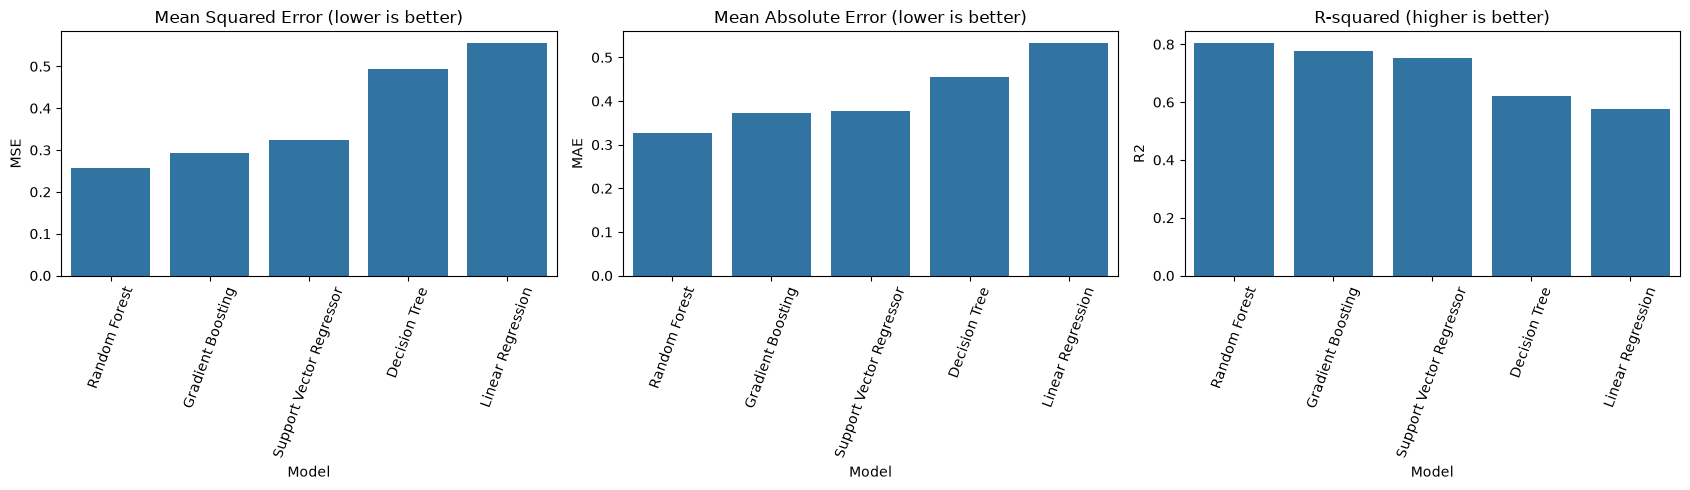

In [8]:
# Visual comparison of the evaluation metrics
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.barplot(data=results_df, x="Model", y="MSE", ax=axes[0])
axes[0].set_title("Mean Squared Error (lower is better)")
axes[0].tick_params(axis="x", rotation=70)

sns.barplot(data=results_df, x="Model", y="MAE", ax=axes[1])
axes[1].set_title("Mean Absolute Error (lower is better)")
axes[1].tick_params(axis="x", rotation=70)

sns.barplot(data=results_df, x="Model", y="R2", ax=axes[2])
axes[2].set_title("R-squared (higher is better)")
axes[2].tick_params(axis="x", rotation=70)

plt.tight_layout()
plt.show()
